### Innovation.
This new version improves upon the last iteration in the following domain:
- sensors precision and ODR from datasheets
- regular sensor sampling rate
- linear kalman filtering on height and its two derivatives

Further iterations shall incorporate a non-linear filter that includes a linearization for $v^2$, $C_d$ as well as $u$ and **B** for modelling the control outputs of the airbrakes. 

In [21]:
import queue
import numpy as np
from typing import Callable, Optional


class HiddenSystemState: 
    timestamp: float = None
    acceleration:float = None
    velocity:float  = None
    height: float = None

    temperature: float = None
    air_density: float = None
    air_pressure: float = None

    def __init__(self,ts,a,v,h,t,ad,ap):
        self.timestamp = ts
        self.acceleration = a
        self.velocity = v
        self.height = h
        self.temperature = t
        self.air_density = ad
        self.air_pressure = ap


    
class Sensor:
    std_dev: float = None
    name: str = ""
    output_data_rate: int = 1 # in Hz
    output_data: queue.Queue = queue.Queue()

    systemState: HiddenSystemState = None
    lastTickTs: float = 0    

    def __init__(self,name_, std_dev_, odr_, systemStateRef_, getTargetVar_: Callable[[HiddenSystemState],float]):
        self.name = name_
        self.std_dev = std_dev_
        self.output_data_rate = odr_
        self.systemState = systemStateRef_
        self.getTargetValue = getTargetVar_

    def _generateSample(self) -> float:
        physicalValue:float = self.getTargetValue(self.systemState)
        z = np.random.normal(physicalValue,self.std_dev,1)
        return z

    def reset(self):
        self.lastTickTs = 0
        self.output_data.clear()

    def tick(self, ts:float):
        """
        Checks the time that has passed since last tick and populates the output_data queue
        according to the ODR.
        """
        if ts - self.lastTickTs > (1.0 / self.output_data_rate):
            self.lastTickTs = ts
            sample = self._generateSample()
            self.output_data.put(sample)

The IMU's have different operation modes, from 4 to 32 or 24g. The maximum deceleration we will experience after motor burnout is (without airbrakes) about -1.21G which means we are safe to use the finest resolution of 4G and will continue under this assumption. 

Important: Testing is required to check, whether the barometers precision holds under the rockets conditions, as it is in a closed tube and experiences acceleration.

In [ ]:
# # Setup States and Sensors
# sysState = HiddenSystemState(ts=3.0, a=-9.81,v=129.0,h=250.0,t=25.0,ad=1.225,ap=101_325)

# primary_imu = Sensor("LSM6DSO32",0.03139,1600,sysState,lambda s: s.acceleration)
# secondary_imu = Sensor("BMI088",0.0262644,1600,sysState, lambda s: s.acceleration)
# barometer = Sensor("DPS368",0.35,26,sysState,lambda s: s.air_pressure)

In [42]:
# The data our algorithm predicts and collects (AirBrakeSoftwareData)
class ABSData:
    rawHeight: float
    kalmanHeight: float

    kalmanVelocity: float

    rawAcceleration: float
    kalmanAcceleration: float

    cdEstimate: float
    apogeeEstimate: float

    def __init__(self,rawH,kalH,kalV,rawA,kalA,cdEst,apogeeEst):
        self.rawHeight = rawH
        self.kalmanHeight = kalH
        self.kalmanVelocity = kalV
        self.rawAcceleration = rawA
        self.kalmanAcceleration = kalA
        self.cdEstimate = cdEst
        self.apogeeEstimate = apogeeEst
    

# The actual simulated data
class FlightLogEntry:
    timestamp: int
    height: float
    verticalVelocity: float
    verticalAcceleration: float

    airbrakeExtension: float

    controlSoftwareData: Oprional[ABSData]
    absExecutionTime: float

    def __init__(self,ts,height,verticalVel,verticalAcc, airbrakeExt, absStruct,absExecutionTime):
        self.timestamp = ts
        self.height = height
        self.verticalVelocity = verticalVel
        self.verticalAcceleration = verticalAcc
        self.airbrakeExtension = airbrakeExt
        self.controlSoftwareData = absStruct
        self.absExecutionTime = absExecutionTime

In [49]:
import math
import time
import numpy as np
from typing import Callable, TypeAlias, Sequence
from scipy import integrate as itg

import helpers
import constants


# max deviation currently around 5%, this could mess up the kalman filter
CODE_RUN_FREQUENCY = 20
TIMESTEP = 1 / CODE_RUN_FREQUENCY


flightLogs: list[FlightLogEntry] = []

"""
    @brief The function that will be called from the simulation looop each iteration.
    @param timestamp [float]
    @param primary_imu [Sensor]
    @param secondary_imu [Sensor]
    @param baro [Sensor]
    @param targetApogee [float]
    @return Extension state of the airbrake [float] as well as the [ABSData] for logging.
"""
AirbrakeControlSoftwareCallback: TypeAlias = Callable[[float, Sensor, Sensor, Sensor, float], tuple[float, ABSData]]


def updateSystemState(state: HiddenSystemState,t:float, h:float, v:float, a:float):
    state.height = h
    state.timestamp = t
    state.velocity = v
    state.acceleration = a
    state.temperature = helpers.tempFromHeight(h)

    state.air_density = helpers.airDensityFromHeight(h)
    state.air_pressure = helpers.airPressureFromHeight(h)


"""
    @brief Runs the simulation.
    @param targetApogee [float]
    @param t0 Simulation start time [float]
    @param h0 initialHeight [float]
    @param t0 initialVelocity [float]
    @param controlSoftware [AirbrakeControlSoftwareCallback]
    @return List of the LogEntries [list<FlightLogEntry>]
"""
def runSimulation(targetApogee,t0, h0, v0, controlSoftware:AirbrakeControlSoftwareCallback) -> Sequence[FlightLogEntry]:
    global SENSOR_SETTING_HEIGHT_READ_NOISEFACTOR,SENSOR_SETTING_VEL_READ_NOISEFACTOR
    flightLogs = []

    systemState  = HiddenSystemState(ts=0, a=0,v=0,h=0,t=0,ad=0,ap=0)


    primary_imu = Sensor("LSM6DSO32",0.03139,1600,systemState,lambda s: s.acceleration)
    secondary_imu = Sensor("BMI088",0.0262644,1600,systemState, lambda s: s.acceleration)
    barometer = Sensor("DPS368",0.35,26,systemState,lambda s: s.height)

    all_sensors = [primary_imu,secondary_imu,barometer]
    """
         Execution order
        <===============>

        1) calculate state & forces
        1.b) let the sensors tick
        2) save state
        3) do logging
        4) execute control software and capture Airbrake ext. for next iteration
        5) return itg variables

    """

    last_control_software_execution = 0
    airbrake_extension_level = 0.0 # since it is set for the k+1
    def dynamicSystem(t,x_data):
        # nonlocal primary_imu, secondary_imu, barometer
        nonlocal flightLogs, airbrake_extension_level, last_control_software_execution, all_sensors
        x = x_data[0]
        v = x_data[1]

        dx_dt = v    # x' = v
        currentAltitudeAirDensity = helpers.airDensityFromHeight(x)

        # We can make this a function of height/velocity to simulate oscillations (maybe between 85° and 95°)
        crossSectionalArea = (math.pi * (constants.ROCKET_OUTER_DIAMETER_M/2)**2) # m²

        # F_D = 1/2 p A C_d v²
        bodyDragForce = (1/2) * currentAltitudeAirDensity * crossSectionalArea * constants.ROCKET_DEFAULT_CD * (v**2)
        airbrakeDragForce = helpers.airbrakeAdditionalDragForce(airbrake_extension_level,constants.ROCKET_AIRBRAKE_DEFAULT_CD,v,currentAltitudeAirDensity)
        dy_dt = -9.81 - (bodyDragForce + airbrakeDragForce)/constants.ROCKET_BURNOUT_MASS

        ## Tell sensors to push into their queue
        for s in all_sensors:
            s.tick(t)
        
        ## Update the system state
        updateSystemState(systemState,t,x,v,dy_dt)

        absUnitLog = None
        absExecutionTime = None
        # Check if it is time for another control software execution to achieve wanted frequency
        if t - last_control_software_execution > TIMESTEP:
            last_control_software_execution = t
            timeBeforeExec = time.perf_counter()
            (airbrake_extension_level, absUnitLog) = controlSoftware(t,primary_imu,secondary_imu,barometer,targetApogee)
            absExecutionTime = time.perf_counter() - timeBeforeExec

            
        logEntry = FlightLogEntry(t,x,v,dy_dt, airbrake_extension_level,absUnitLog,absExecutionTime)
        flightLogs.append(logEntry)

        return [dx_dt, dy_dt]

    # The max_step is a problem right now. Our check would allow .9 TS without a CS retrigger
    # and then if it did 1 TS we would have 1.9 TS instead of 1TS. As a hotfix I decreased granularity to TS/10
    # so that the filters aren't thrown off because of too much inconsistency.
    solver = itg.RK45(dynamicSystem, t0, [h0, v0], 500, max_step=TIMESTEP/10) 
    stepCount = 0
    while solver.status == "running":
        solver.step()
        stepCount += 1

        # Checking of y = 0 is hit to terminate simulation
        if solver.y[0] <= 0:
            break

    print(f"Solver status: {solver.status}. Steps: {stepCount}")
    return flightLogs



## ABS Software
#### State Filtering
We use a Kalman filter to filter the z-acceleration, z-velocity and height of the rocket. Our state vector is 
$$
x = \begin{bmatrix} x \\  \dot x \\ \ddot x \end{bmatrix}
$$ 


I'll start off with a simplified measurement vector that only includes one of the two IMU readings.
$$ 
z = \begin{bmatrix} acc_{1} \\ \text{height} \end{bmatrix}
$$

The state transitiion matrix we get 

$$
F = \begin{bmatrix}1& dt& dt²/2\\0& 1& dt\\0& 0& 1 \end{bmatrix}
$$

where *dt* is our TIMESTEP and constant.

To estimate the process noise, we will start out with filterpy's discrete white noise according to a wiener process.


In [50]:
from filterpy import kalman
from filterpy.common import Q_discrete_white_noise

# Data on our sensors.



WHITE_NOISE_VAR = 0.5 # total guess

kalmanFilter_ = None
def airbrakeControlSoftware(t:float, imu1: Sensor, imu2: Sensor, baro: Sensor, targetApogee: float) -> tuple[float,Optional[ABSData]]:
    # Get sensor measurements if available
    z_acc1 = imu1._generateSample()
    z_height = baro._generateSample()

    # Add outlier detection here (to check if a sensor failed.)
    # If detected, change kalmanFilter measurement matrix H to ignore it

    global kalmanFilter_
    if kalmanFilter_ == None:
        # Setup the Kalman Filter
        kalmanFilter_ = kalman.KalmanFilter(dim_x=3,dim_z=2)

        # Process Noise: For process noise, assume discrete time Wiener process 
        kalmanFilter_.Q = Q_discrete_white_noise(dim=3,dt=TIMESTEP,var=WHITE_NOISE_VAR)

        # State Transition Matrix
        kalmanFilter_.F = np.array([[1,TIMESTEP,TIMESTEP**2 / 2],
                                    [0,1, TIMESTEP],
                                    [0,0,1]])

        # Measurement Function: only using one of the IMU's for now
        kalmanFilter_.H = np.array([[0,0,1],
                                   [1,0,0]])

        # Measurement Noise Matrix: starting with no cov
        kalmanFilter_.R = np.array([[imu1.std_dev**2,0],
                                   [0,baro.std_dev**2]])

        # Inital conditions: Use first measurement or default value
        i_x,i_xv = (z_height,baro.std_dev**2) if z_height else (200,100)
        i_v,i_vv = (120,100)
        i_a,i_av = (z_acc1,imu1.std_dev**2) if z_acc1 else (-10,50)
        kalmanFilter_.x = np.array([1,2,3])
        
        # Inital Variance: If measurement use sensors variance, else big one to show uncertainty
        kalmanFilter_.P = np.array([[i_xv,0,0],
                                    [0,i_vv,0],
                                    [0,0,i_av]])



    # Predict and update
    kalmanFilter_.predict()
    kalmanFilter_.update(np.array([z_acc1, z_height]))

    estState = kalmanFilter_.x
    logUnit = ABSData(rawH=z_height, rawA=z_acc1, kalH=estState[0], kalV=estState[1], kalA=estState[2], apogeeEst=0, cdEst=0)

    
    return (1.0, logUnit)

flightData:Sequence[FlightLogEntry] = runSimulation(960,constants.SIM_T0,constants.SIM_T0_HEIGHT,constants.SIM_T0_VELOCITY,airbrakeControlSoftware)

Solver status: running. Steps: 4898


## Data Analysis

Apogee: 920.896509756781


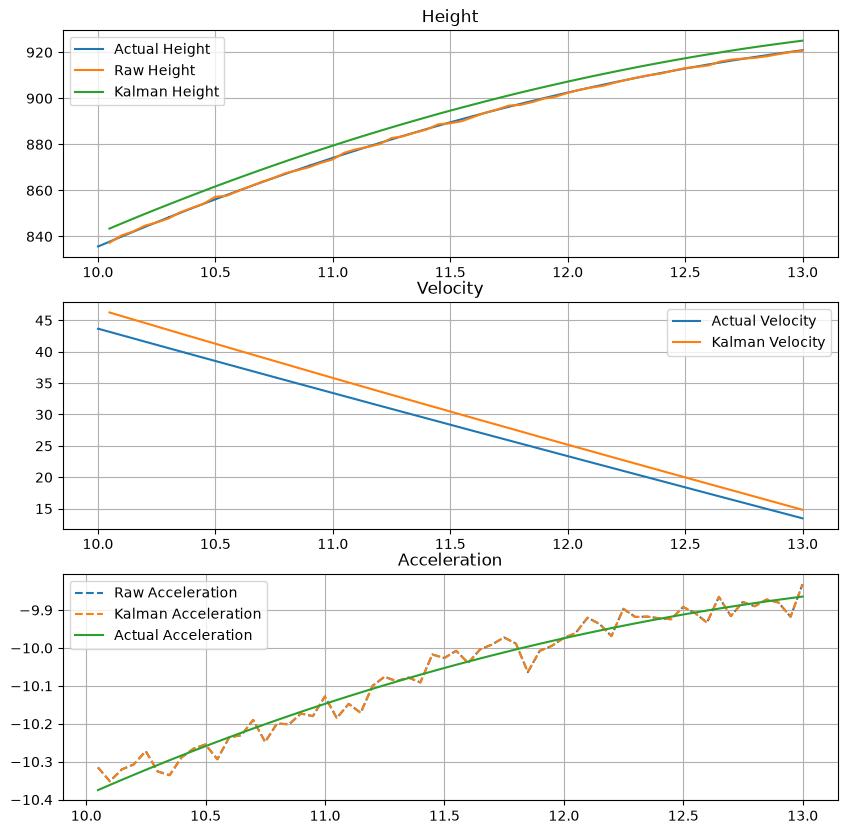

In [56]:
from matplotlib import pyplot as plt

dataStartTime = 10
dataEndTime = 13

# Analysing the data
t = np.array([i.timestamp for i in flightData if dataStartTime <= i.timestamp <= dataEndTime])
h = np.array([i.height for i in flightData if dataStartTime <= i.timestamp <= dataEndTime])

# filter out the AbsData timestamps, raw height and kalman height for plotting
absTimestamps = np.array([i.timestamp for i in flightData if i.controlSoftwareData is not None and dataStartTime <= i.timestamp <= dataEndTime])
rawHeights = np.array([i.controlSoftwareData.rawHeight for i in flightData if i.controlSoftwareData is not None and dataStartTime <= i.timestamp <= dataEndTime])
kalmanHeights = np.array([i.controlSoftwareData.kalmanHeight for i in flightData if i.controlSoftwareData is not None and dataStartTime <= i.timestamp <= dataEndTime])

actualVelocity = np.array([i.verticalVelocity for i in flightData if dataStartTime <= i.timestamp <= dataEndTime])
kalmanVelocity = np.array([i.controlSoftwareData.kalmanVelocity for i in flightData if i.controlSoftwareData is not None and dataStartTime <= i.timestamp <= dataEndTime])
 

# for accelerations
rawAccelerations = np.array([i.controlSoftwareData.rawAcceleration for i in flightData if i.controlSoftwareData is not None and dataStartTime <= i.timestamp <= dataEndTime])
kalmanAccelerations = np.array([i.controlSoftwareData.kalmanAcceleration for i in
    flightData if i.controlSoftwareData is not None and dataStartTime <= i.timestamp <= dataEndTime])
actualAccelerations = np.array([i.verticalAcceleration for i in flightData if i.controlSoftwareData is not None and dataStartTime <= i.timestamp <= dataEndTime])


print(f"Apogee: {max(h)}")


fig, axs = plt.subplots(3,1,figsize=(10,10))
axs[0].plot(t,h,label="Actual Height")
axs[0].plot(absTimestamps,rawHeights,label="Raw Height")
axs[0].plot(absTimestamps,kalmanHeights,label="Kalman Height")
axs[0].set_title("Height")
axs[0].legend()
axs[0].grid(True)

axs[1].plot(t,actualVelocity,label="Actual Velocity")
axs[1].plot(absTimestamps,kalmanVelocity,label="Kalman Velocity")
axs[1].set_title("Velocity")
axs[1].legend()
axs[1].grid(True)

axs[2].plot(absTimestamps,rawAccelerations,label="Raw Acceleration",linestyle="dashed")
axs[2].plot(absTimestamps,kalmanAccelerations,label="Kalman Acceleration",linestyle="dashed")
axs[2].plot(absTimestamps,actualAccelerations,label="Actual Acceleration")
axs[2].set_title("Acceleration")
axs[2].legend()


plt.grid(True)
plt.show()
